Random Oversampling balanced our classes by copy-pasting existing Non-Petrol rows. The issue: copies are identical to the originals, so the model can start memorizing exact rows instead of learning the underlying pattern of what makes a car Non-Petrol.

SMOTE (Synthetic Minority Oversampling Technique) fixes this by generating brand-new, synthetic minority-class examples that don't already exist in the data — instead of just duplicating what's there.

# The Core Idea

For each minority-class sample, SMOTE:

1. Finds its k nearest neighbors (typically k=5) within the same minority class, based on feature similarity (e.g., similar Mileage, Price, Engine_CC).

2. Randomly picks one of those neighbors.

3. Draws a straight line (in feature space) connecting the original point and the chosen neighbor.

4. Places a new synthetic point somewhere along that line (at a random position between the two).

**Starting point (same as before):**

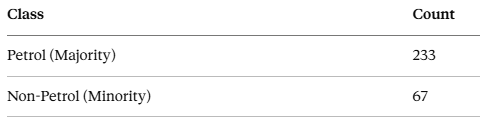

SMOTE needs to generate 166 synthetic Non-Petrol rows to match the majority class. For each synthetic row, it:

Picks a real Non-Petrol car (say, a Diesel SUV with Mileage=14.9 kmpl, Price=30 Lakh)

Finds a similar real Non-Petrol car nearby (say, another Diesel car with Mileage=16.3 kmpl, Price=28 Lakh)

Creates a new synthetic row somewhere between them — e.g., Mileage=15.5 kmpl, Price=29.2 Lakh — with interpolated values across all numeric features (Price, Kilometers_Driven, Mileage, Engine_CC, Power_BHP, etc.)

Same final size as random oversampling — but this time, 166 of those Non-Petrol rows are new, never-before-seen combinations of feature values, not exact duplicates.

In [ ]:
import pandas as pd
from imblearn.over_sampling import SMOTE

df = pd.read_csv("used_cars_dataset.csv")
df["Class"] = df["Fuel_Type"].apply(lambda x: "Petrol" if x == "Petrol" else "Non-Petrol")

# SMOTE requires numeric features
X = df[["Price", "Kilometers_Driven", "Mileage_kmpl", "Engine_CC", "Power_BHP"]]
y = df["Class"]

smote = SMOTE(k_neighbors=5, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print(y_resampled.value_counts())
# Petrol        233
# Non-Petrol    233
print("Original rows:", len(X), "| After SMOTE:", len(X_resampled))
# Original rows: 300 | After SMOTE: 466

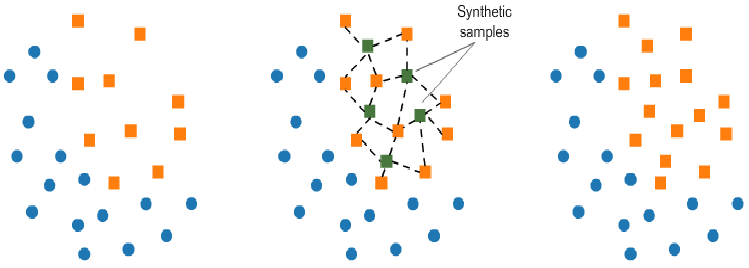![image.png]()